In [2]:
!pip install -q transformers datasets accelerate sentencepiece scikit-learn seaborn matplotlib pandas

In [1]:
import torch
import transformers
import datasets
import accelerate
import huggingface_hub
import fsspec

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Fsspec:", fsspec.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 4.48.3
Datasets: 3.2.0
Accelerate: 1.2.1
Hugging Face Hub: 0.36.2
Fsspec: 2024.9.0

GPU Available: True
GPU: Tesla T4


In [2]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

print("XLM-R loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


XLM-R loaded successfully!


In [3]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Please enable T4 GPU from Runtime → Change runtime type")

GPU Available: True
GPU Name: Tesla T4


In [4]:
from google.colab import files

uploaded = files.upload()

Saving Climate-Stance-Detection-for-Indic-Languages-main (1).zip to Climate-Stance-Detection-for-Indic-Languages-main (1).zip


In [5]:
import zipfile
import os

zip_path = next(iter(uploaded.keys()))

extract_path = "/content/climate_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import pandas as pd

dataset_folder = os.path.join(
    extract_path,
    "Climate-Stance-Detection-for-Indic-Languages-main",
    "dataset"
)

train_df = pd.read_csv(
    os.path.join(dataset_folder, "final_train.csv")
)

val_df = pd.read_csv(
    os.path.join(dataset_folder, "final_validation.csv")
)

print("Training Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)

display(train_df.head())

Training Shape: (4836, 7)
Validation Shape: (1209, 7)


,text,label,language,split,source,translation_status,original_id
0,Fracking wells leak massive quantities of meth...,NaN,English,train,combined_dataset.csv,original,train_0
1,Brilliant talk from @GeorgeMonbiot #Dali Lama ...,NaN,English,train,combined_dataset.csv,original,train_1
2,Working with artists & culture is key to weave...,NaN,English,train,combined_dataset.csv,original,train_2
3,A warning sign that some scientists worry coul...,Favour,English,train,combined_dataset.csv,original,train_3
4,The Arctic had the power to put the United Sta...,NaN,English,train,combined_dataset.csv,original,train_4


In [7]:
# Fill blank labels
train_df["label"] = train_df["label"].fillna("None")
val_df["label"] = val_df["label"].fillna("None")

# Clean text
train_df["text"] = train_df["text"].fillna("").astype(str).str.strip()
val_df["text"] = val_df["text"].fillna("").astype(str).str.strip()

# Remove empty comments
train_df = train_df[train_df["text"] != ""].copy()
val_df = val_df[val_df["text"] != ""].copy()

# Label mapping
label_mapping = {
    "Favour": 0,
    "Against": 1,
    "None": 2
}

train_df["label"] = train_df["label"].str.strip()
val_df["label"] = val_df["label"].str.strip()

train_df["labels"] = train_df["label"].map(label_mapping)
val_df["labels"] = val_df["label"].map(label_mapping)

assert train_df["labels"].notna().all()
assert val_df["labels"].notna().all()

train_df["labels"] = train_df["labels"].astype(int)
val_df["labels"] = val_df["labels"].astype(int)

print("Preprocessing completed!")
print(train_df["label"].value_counts())

Preprocessing completed!
label
None       2118
Favour     2043
Against     675
Name: count, dtype: int64


In [8]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={
        0: "Favour",
        1: "Against",
        2: "None"
    },
    label2id={
        "Favour": 0,
        "Against": 1,
        "None": 2
    }
)

print("XLM-RoBERTa loaded successfully!")

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


XLM-RoBERTa loaded successfully!


In [9]:
from datasets import Dataset

train_dataset = Dataset.from_dict({
    "text": train_df["text"].tolist(),
    "labels": train_df["labels"].tolist()
})

val_dataset = Dataset.from_dict({
    "text": val_df["text"].tolist(),
    "labels": val_df["labels"].tolist()
})

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("Tokenization completed!")

Map:   0%|          | 0/4836 [00:00<?, ? examples/s]

Map:   0%|          | 0/1209 [00:00<?, ? examples/s]

Tokenization completed!


In [10]:
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("\nSample tokenized data:")
print(train_dataset[0].keys())

print("\nSample labels:")
print(train_dataset[0]["labels"])

print("\nModel device:")
print(next(model.parameters()).device)

Training samples: 4836
Validation samples: 1209

Sample tokenized data:
dict_keys(['labels', 'input_ids', 'attention_mask'])

Sample labels:
2

Model device:
cpu


In [11]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("Currently using CPU")

CUDA Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [12]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["labels"].values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("Class Weights:")

for i, weight in enumerate(class_weights):
    print(
        ["Favour", "Against", "None"][i],
        round(weight.item(), 4)
    )

Class Weights:
Favour 0.789
Against 2.3881
None 0.7611


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "precision_macro": precision_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            labels, predictions,
            average="weighted",
            zero_division=0
        ),

        "micro_f1": f1_score(
            labels, predictions,
            average="micro",
            zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            labels, predictions
        ),

        "mcc": matthews_corrcoef(labels, predictions)
    }

In [14]:
from transformers import Trainer

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        **kwargs
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_function(
            logits.view(-1, 3),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss

In [15]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="/content/xlmr_climate_results",

    num_train_epochs=4,

    learning_rate=2e-5,

    per_device_train_batch_size=8,

    per_device_eval_batch_size=8,

    gradient_accumulation_steps=2,

    weight_decay=0.01,

    warmup_ratio=0.1,

    evaluation_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="steps",

    logging_steps=25,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    fp16=True,

    save_total_limit=2,

    report_to="none",

    seed=42
)

print("Training configuration completed!")

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1575: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Training configuration completed!


In [16]:
trainer = WeightedTrainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("XLM-RoBERTa training completed!")

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,Macro F1,Weighted F1,Micro F1,Balanced Accuracy,Mcc
1,0.918700,0.874584,0.655087,0.626851,0.600857,0.606142,0.650297,0.655087,0.600857,0.436220
2,0.714800,0.842314,0.712986,0.691943,0.643881,0.658232,0.706342,0.712986,0.643881,0.521958
3,0.525500,0.853594,0.733664,0.705540,0.670597,0.682623,0.728646,0.733664,0.670597,0.557698


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,Macro F1,Weighted F1,Micro F1,Balanced Accuracy,Mcc
1,0.918700,0.874584,0.655087,0.626851,0.600857,0.606142,0.650297,0.655087,0.600857,0.436220
2,0.714800,0.842314,0.712986,0.691943,0.643881,0.658232,0.706342,0.712986,0.643881,0.521958
3,0.312900,0.966323,0.736146,0.709569,0.696952,0.700361,0.734127,0.736146,0.696952,0.569167


XLM-RoBERTa training completed!


In [17]:
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report

# Get predictions from the best model
predictions_output = trainer.predict(val_dataset)

y_true = predictions_output.label_ids

y_pred = np.argmax(
    predictions_output.predictions,
    axis=1
)

target_names = ["Favour", "Against", "None"]

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=target_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("FINAL CLASSIFICATION REPORT")

display(report_df.round(4))

FINAL CLASSIFICATION REPORT


,precision,recall,f1-score,support
Favour,0.7222,0.8363,0.7751,513.0000
Against,0.6104,0.5595,0.5839,168.0000
None,0.7961,0.6951,0.7422,528.0000
accuracy,0.7361,0.7361,0.7361,0.7361
macro avg,0.7096,0.6970,0.7004,1209.0000
weighted avg,0.7389,0.7361,0.7341,1209.0000


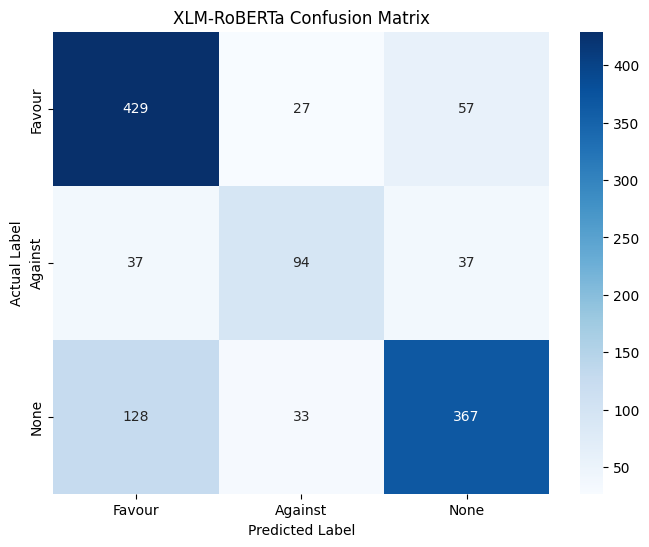

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("XLM-RoBERTa Confusion Matrix")

plt.show()

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef
)

overall_results = {
    "Accuracy": accuracy_score(y_true, y_pred),

    "Precision (Macro)": precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Recall (Macro)": recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    ),

    "Micro F1": f1_score(
        y_true, y_pred,
        average="micro",
        zero_division=0
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_true, y_pred
    ),

    "MCC": matthews_corrcoef(y_true, y_pred)
}

overall_df = pd.DataFrame(
    list(overall_results.items()),
    columns=["Evaluation Metric", "Score"]
)

overall_df["Score"] = overall_df["Score"].round(4)

display(overall_df)

,Evaluation Metric,Score
0,Accuracy,0.7361
1,Precision (Macro),0.7096
2,Recall (Macro),0.6970
3,Macro F1,0.7004
4,Weighted F1,0.7341
5,Micro F1,0.7361
6,Balanced Accuracy,0.6970
7,MCC,0.5692


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

language_results = []

val_languages = val_df["language"].reset_index(drop=True)

for language in val_languages.unique():

    indices = np.where(
        val_languages.values == language
    )[0]

    actual = y_true[indices]
    predicted = y_pred[indices]

    language_results.append({

        "Language": language,

        "Accuracy": accuracy_score(
            actual, predicted
        ),

        "Precision": precision_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            actual, predicted,
            average="weighted",
            zero_division=0
        ),

        "Samples": len(indices)
    })

language_results_df = pd.DataFrame(language_results)

display(language_results_df.round(4))

,Language,Accuracy,Precision,Recall,Macro F1,Weighted F1,Samples
0,English,0.7395,0.7037,0.6983,0.6975,0.7378,403
1,Hindi,0.7419,0.7184,0.7122,0.7130,0.7404,403
2,Bengali,0.7270,0.7093,0.6804,0.6904,0.7242,403


In [21]:
import os

results_dir = "/content/xlmr_final_results"

os.makedirs(results_dir, exist_ok=True)

overall_df.to_csv(
    f"{results_dir}/overall_metrics.csv",
    index=False
)

report_df.to_csv(
    f"{results_dir}/classification_report.csv"
)

language_results_df.to_csv(
    f"{results_dir}/language_wise_metrics.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=target_names,
    columns=target_names
).to_csv(
    f"{results_dir}/confusion_matrix.csv"
)

print("All evaluation reports saved successfully!")

All evaluation reports saved successfully!


In [22]:
import os

results_dir = "/content/xlmr_final_results"

os.makedirs(results_dir, exist_ok=True)

overall_df.to_csv(
    f"{results_dir}/overall_metrics.csv",
    index=False
)

report_df.to_csv(
    f"{results_dir}/classification_report.csv"
)

language_results_df.to_csv(
    f"{results_dir}/language_wise_metrics.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=target_names,
    columns=target_names
).to_csv(
    f"{results_dir}/confusion_matrix.csv"
)

print("All evaluation reports saved successfully!")

All evaluation reports saved successfully!


In [25]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [26]:
import os

MODEL_SAVE_PATH = (
    "/content/drive/MyDrive/"
    "Climate_Stance_XLMR/model"
)

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

# Save best trained model
trainer.save_model(MODEL_SAVE_PATH)

# Save tokenizer
tokenizer.save_pretrained(MODEL_SAVE_PATH)

print("Model saved successfully!")

Model saved successfully!


In [27]:
import shutil

RESULTS_SAVE_PATH = (
    "/content/drive/MyDrive/"
    "Climate_Stance_XLMR/results"
)

os.makedirs(RESULTS_SAVE_PATH, exist_ok=True)

for filename in os.listdir(results_dir):

    source = os.path.join(results_dir, filename)

    destination = os.path.join(
        RESULTS_SAVE_PATH, filename
    )

    shutil.copy2(source, destination)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [28]:
# Create a prediction results dataframe

prediction_df = val_df.reset_index(drop=True).copy()

prediction_df["Actual"] = [
    ["Favour", "Against", "None"][i]
    for i in y_true
]

prediction_df["Predicted"] = [
    ["Favour", "Against", "None"][i]
    for i in y_pred
]

prediction_df["Correct"] = (
    prediction_df["Actual"] == prediction_df["Predicted"]
)

# Save all predictions
prediction_df.to_csv(
    f"{RESULTS_SAVE_PATH}/all_predictions.csv",
    index=False
)

# Extract incorrect predictions
errors_df = prediction_df[
    prediction_df["Correct"] == False
]

errors_df.to_csv(
    f"{RESULTS_SAVE_PATH}/incorrect_predictions.csv",
    index=False
)

print("Total validation examples:", len(prediction_df))
print("Correct predictions:", prediction_df["Correct"].sum())
print("Incorrect predictions:", len(errors_df))

display(errors_df[
    ["text", "language", "Actual", "Predicted"]
].head(15))

Total validation examples: 1209
Correct predictions: 890
Incorrect predictions: 319


,text,language,Actual,Predicted
1,By the end of the century the chance of Sandy-...,English,None,Favour
6,Scientists agree that future storms will be sl...,English,None,Favour
9,Global warming has been behind every catastrop...,English,Favour,Against
15,Harvard climate action plan explicitly recogni...,English,Favour,None
28,Thousands more homes are damaged by Florence b...,English,None,Favour
29,A lot of Americans are growing far more concer...,English,Favour,Against
30,Solar activity has varied a bit while global t...,English,None,Against
44,Today’s ice storm is likely to be more damagin...,English,None,Favour
47,If we allow the Environmental Protection Agenc...,English,Against,Favour
48,A carbon pricing policy is essential if humani...,English,Favour,None
